# IBD-Risk AI — Machine-learning prediction of IBD in Saudi youth
**Team NH-74 · Track 3: AI-driven clinical decision support**

This notebook trains and compares several models that classify **IBD vs. no IBD** from 61 variables in 10 groups:
demographics, family history, diet, lifestyle, medication & antibiotics, birth mode & early life,
microbiome diversity, inflammatory biomarkers, metabolism biomarkers and red flags.
It then picks the best model, tunes its decision threshold, tests it on held-out data, explains it with SHAP,
and shows how to score a new person.

> ⚠️ **Synthetic data only.** The dataset is simulated. All metrics show how well the model recovers the
> synthetic generation formula. They are **not** clinical or diagnostic accuracy, and SHAP explanations reflect
> that formula, not real biology.

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.base import clone

# Project modules (same code as train.py, so the notebook reproduces the saved model)
from features import load_raw, encode, FEATURES, GROUPS, EXCLUDED, NO_NARRATE, DISCLAIMER
from train import (candidates, pick_threshold, metrics_at, precision_at_recall_table,
                   bootstrap_auc_ci, calibration_slope_intercept, SEED, MIN_RECALL, TIERS)
from explain import make_explainer
%matplotlib inline

pd.set_option("display.precision", 3)
GREEN, RED, GREY = "#1f6f5c", "#c0392b", "#999999"

## 2. Load the data
`keep_default_na=False` matters: in `family_history_IBD` and `childhood_antibiotic_exposure`, the text **"None"** is a real
category (no family history / no exposure). By default pandas would read it as missing.

In [2]:
raw = load_raw()
y = raw["synthetic_IBD_outcome"].astype(int).values
print(f"{raw.shape[0]} people, {raw.shape[1]} columns")
print(f"IBD prevalence: {y.mean():.1%}  ({y.sum()} IBD / {(1 - y).sum()} no IBD)")
raw.head()

2500 people, 68 columns
IBD prevalence: 24.7%  (618 IBD / 1882 no IBD)


,patient_id,age_years,sex,BMI_kg_m2,family_history_IBD,family_history_autoimmune,fiber_g_day,fast_food_times_week,ultra_processed_food_times_week,fruit_vegetable_servings_day,...,fecal_butyrate_umol_g,primary_to_secondary_bile_acid_ratio,tryptophan_ug_mL,indole_3_acetic_acid_ug_mL,palmitic_acid_ug_mL,myristic_acid_ug_mL,arachidonic_acid_ug_mL,histidine_ug_mL,total_triglycerides_mg_dL,metabolomic_risk_score_0_1
0,SAUDI_SYN_03631,24,Female,22.0,None,No,30.4,2,7,2.2,...,59.21,1.624,20.28,2.510,156.4,17.35,99.2,15.28,137.2,0.282
1,SAUDI_SYN_01275,29,Female,24.5,None,No,20.7,5,5,3.1,...,60.58,1.993,14.45,2.296,100.3,15.97,74.4,13.74,177.5,0.536
2,SAUDI_SYN_01636,26,Male,16.0,First-degree relative,No,13.9,0,8,4.4,...,38.89,1.406,16.12,1.950,105.8,16.10,97.4,8.57,161.5,0.455
3,SAUDI_SYN_02944,24,Female,16.9,None,No,25.7,1,4,4.6,...,60.84,1.394,16.14,3.509,119.0,25.36,97.2,17.12,144.2,0.202
4,SAUDI_SYN_01461,26,Female,24.0,None,No,17.4,0,5,3.0,...,28.39,2.224,13.04,3.981,136.3,13.61,63.6,7.85,135.2,0.498


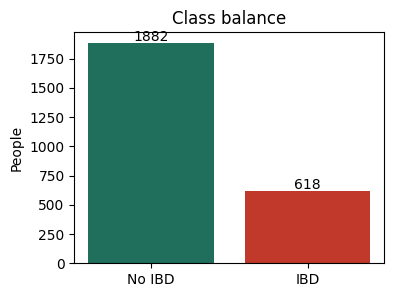

In [3]:
fig, ax = plt.subplots(figsize=(4, 3))
counts = pd.Series(y).map({0: "No IBD", 1: "IBD"}).value_counts()
ax.bar(counts.index, counts.values, color=[GREEN, RED])
for i, v in enumerate(counts.values):
    ax.text(i, v + 20, str(v), ha="center")
ax.set(title="Class balance", ylabel="People")
plt.show()

## 3. Choosing the input variables (no leakage)
The dataset's README sheet sets the rules:
- `patient_id`, `synthetic_IBD_outcome` and `synthetic_IBD_risk_probability` are **never** inputs; the last two contain the answer.
- The composite scores (`dysbiosis_index`, `microbial_risk_score`, `metabolomic_risk_score`) are near-copies of the target, so we use their raw components instead (**README Option A**).
- `oral_contraceptive_use` is 0 for every male, so it would let the model learn sex indirectly. It is excluded.

That leaves **61 variables in 10 groups**:

In [4]:
display(pd.DataFrame([(g, len(c), ", ".join(c)) for g, c in GROUPS.items()],
                     columns=["Group", "#", "Variables"]).style.hide(axis="index"))
print("Excluded:", EXCLUDED)

Group,#,Variables
Demographic data,3,"age_years, sex, BMI_kg_m2"
Family history,2,"family_history_IBD, family_history_autoimmune"
Diet,10,"fiber_g_day, fast_food_times_week, ultra_processed_food_times_week, fruit_vegetable_servings_day, sugary_drinks_times_week, red_processed_meat_times_week, fermented_food_times_week, fish_times_week, dates_times_week, fried_food_times_week"
Lifestyle,7,"physical_activity_min_week, sedentary_hours_day, sleep_hours, sleep_quality, stress_level, smoking, vaping"
Medication and antibiotics,6,"antibiotic_courses_year, antibiotic_use_past_3_months, broad_spectrum_antibiotic, NSAID_use_times_month, PPI_use, childhood_antibiotic_exposure"
Birth mode and early life,4,"birth_mode, breastfeeding_months, childhood_GI_infection, childhood_infection_count"
Microbiome diversity,7,"alpha_diversity_Shannon, butyrate_producer_abundance_pct, Faecalibacterium_abundance_pct, Roseburia_abundance_pct, Bacteroides_abundance_pct, Proteobacteria_abundance_pct, Firmicutes_Bacteroidetes_ratio"
Inflammatory biomarkers,3,"fecal_calprotectin_ug_g, CRP_mg_L, vitamin_D_ng_mL"
Metabolism related biomarkers,10,"serum_butyrate_umol_L, fecal_butyrate_umol_g, primary_to_secondary_bile_acid_ratio, tryptophan_ug_mL, indole_3_acetic_acid_ug_mL, palmitic_acid_ug_mL, myristic_acid_ug_mL, arachidonic_acid_ug_mL, histidine_ug_mL, total_triglycerides_mg_dL"
Red flags,9,"perianal_fistula_history, recurrent_aphthous_ulcers, erythema_nodosum_history, pyoderma_gangrenosum_history, hidradenitis_suppurativa_history, PSC_or_elevated_LFTs, unprovoked_VTE_history, appendectomy_history, tonsillectomy_history"


Excluded: ['patient_id', 'synthetic_IBD_outcome', 'synthetic_IBD_risk_probability', 'dysbiosis_index_0_100', 'microbial_risk_score_0_1', 'metabolomic_risk_score_0_1', 'oral_contraceptive_use']


## 4. Encoding
Categories become numbers, following README §11:
- Yes/No → 1/0, Male = 1, Cesarean = 1
- Ordered scales: family history None < second-degree < first-degree < multiple; childhood antibiotics None < 1-2 < 3+; sleep quality Good < Moderate < Poor; stress Low < Moderate < High

In [5]:
X = encode(raw)
assert list(X.columns) == FEATURES and X.shape[1] == 61
assert not set(X.columns) & set(EXCLUDED), "leakage!"
assert not X.isna().any().any()
print("Feature matrix:", X.shape, "- no missing values, no leakage columns")
X.describe().T.head(12)

Feature matrix: (2500, 61) - no missing values, no leakage columns


,count,mean,std,min,25%,50%,75%,max
age_years,2500.0,22.702,4.626,15.0,19.0,23.0,27.0,30.0
sex,2500.0,0.488,0.500,0.0,0.0,0.0,1.0,1.0
BMI_kg_m2,2500.0,23.879,4.193,16.0,21.0,23.7,26.8,37.7
family_history_IBD,2500.0,0.196,0.577,0.0,0.0,0.0,0.0,3.0
family_history_autoimmune,2500.0,0.144,0.351,0.0,0.0,0.0,0.0,1.0
fiber_g_day,2500.0,18.989,6.817,4.0,14.1,19.1,23.8,40.2
fast_food_times_week,2500.0,2.123,1.463,0.0,1.0,2.0,3.0,8.0
ultra_processed_food_times_week,2500.0,7.025,2.636,0.0,5.0,7.0,9.0,18.0
fruit_vegetable_servings_day,2500.0,3.089,1.455,0.0,2.1,3.1,4.1,8.9
sugary_drinks_times_week,2500.0,3.994,1.948,0.0,3.0,4.0,5.0,12.0


## 5. Quick look: which variables relate to IBD?
Spearman correlation of each input with the outcome. This is a first look only; the model learns all of them jointly.

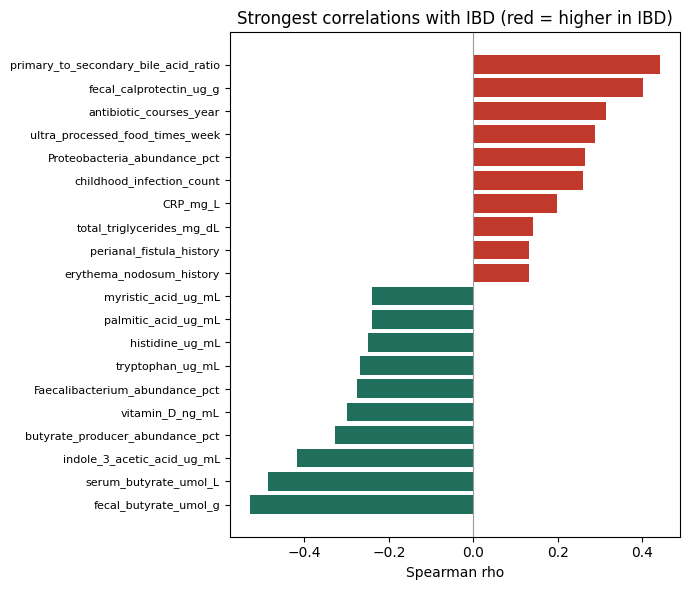

In [6]:
corr = X.apply(lambda c: pd.Series(c).corr(pd.Series(y), method="spearman")).sort_values()
top = pd.concat([corr.head(10), corr.tail(10)])
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=[RED if v > 0 else GREEN for v in top.values])
ax.axvline(0, color=GREY, lw=0.8)
ax.set(title="Strongest correlations with IBD (red = higher in IBD)", xlabel="Spearman rho")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

## 6. Train / test split
80% for training and model selection, 20% (**500 people**) locked away as a final test set,
stratified so both keep the same IBD rate.

In [7]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train {len(y_tr)} (IBD {y_tr.mean():.1%})   test {len(y_te)} (IBD {y_te.mean():.1%})")

train 2000 (IBD 24.7%)   test 500 (IBD 24.8%)


## 7. Model comparison — nested cross-validation
Five candidates, each tuned **inside** each fold (inner 5-fold, scored on PR-AUC) and evaluated on the outer fold it never saw:

| Model | Why it's a candidate |
|---|---|
| Logistic Regression (L2) | Interpretable baseline (abstract) |
| Sparse Logistic Regression (L1) | Used successfully in Saudi microbiome studies (report) |
| Logistic Regression + splines | Lets each variable have a curved effect |
| Random Forest | Non-linear, robust to outliers (report) |
| Gradient Boosting (HistGB) | Same model family as XGBoost (report) |

Plus a 50/50 **ensemble** of the best linear model and gradient boosting.

**Ranking metric: PR-AUC.** It summarizes precision across every recall level and suits imbalanced data (25% IBD).

⏱️ This cell takes about 5 minutes, mostly for gradient boosting.

In [8]:
outer = StratifiedKFold(5, shuffle=True, random_state=SEED)
searches, oof, rows = candidates(), {}, []

def summarize(name, p):
    m = metrics_at(y_tr, p, pick_threshold(y_tr, p))
    return {"model": name, "PR_AUC": average_precision_score(y_tr, p), "ROC_AUC": roc_auc_score(y_tr, p),
            "Brier": brier_score_loss(y_tr, p), "precision": m["precision"], "recall": m["recall"],
            "accuracy": m["accuracy"], "F1": m["f1"]}

for name, search in searches.items():
    oof[name] = cross_val_predict(search, X_tr, y_tr, cv=outer, method="predict_proba")[:, 1]
    rows.append(summarize(name, oof[name]))
    print(f"done: {name}")

lin = ["Logistic Regression (L2)", "Sparse Logistic Regression (L1)", "Logistic Regression + splines"]
best_lin = max(lin, key=lambda n: average_precision_score(y_tr, oof[n]))
ens = f"Ensemble ({best_lin} + HistGB)"
oof[ens] = (oof[best_lin] + oof["Gradient Boosting (HistGB)"]) / 2
rows.append(summarize(ens, oof[ens]))

cmp = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
cmp

done: Logistic Regression (L2)


done: Sparse Logistic Regression (L1)


done: Logistic Regression + splines


done: Random Forest


done: Gradient Boosting (HistGB)


,model,PR_AUC,ROC_AUC,Brier,precision,recall,accuracy,F1
0,Sparse Logistic Regression (L1),0.935,0.975,0.053,0.867,0.860,0.933,0.864
1,Logistic Regression (L2),0.929,0.973,0.053,0.870,0.856,0.933,0.863
2,Ensemble (Sparse Logistic Regression (L1) + Hi...,0.929,0.973,0.056,0.836,0.854,0.922,0.845
3,Logistic Regression + splines,0.924,0.972,0.062,0.827,0.858,0.920,0.842
4,Gradient Boosting (HistGB),0.903,0.961,0.069,0.756,0.864,0.897,0.806
5,Random Forest,0.893,0.960,0.082,0.751,0.862,0.895,0.803


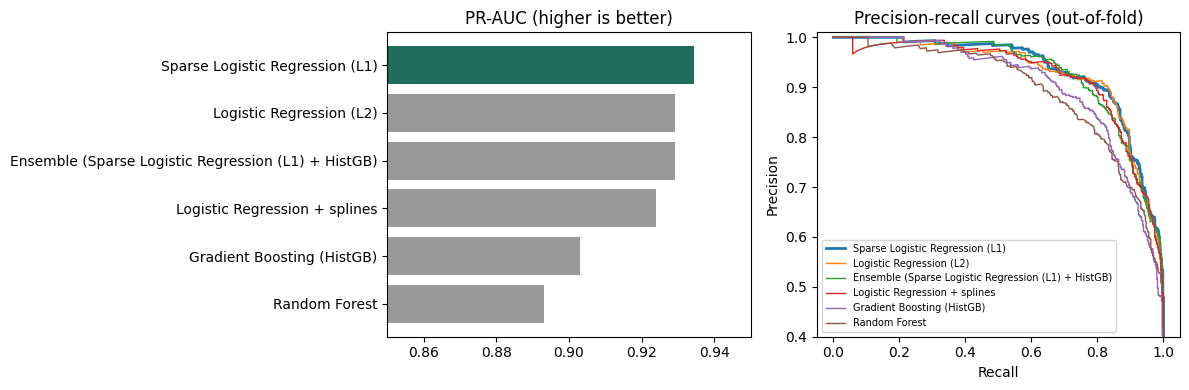

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
c = cmp.iloc[::-1]
ax[0].barh(c["model"], c["PR_AUC"], color=[GREEN if i == 0 else GREY for i in c.index])
ax[0].set(xlim=(0.85, 0.95), title="PR-AUC (higher is better)")
for n in cmp["model"]:
    P, R, _ = precision_recall_curve(y_tr, oof[n])
    ax[1].plot(R, P, lw=2 if n == cmp.loc[0, "model"] else 1, label=n)
ax[1].set(title="Precision-recall curves (out-of-fold)", xlabel="Recall", ylabel="Precision", ylim=(0.4, 1.01))
ax[1].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

## 8. Pick the best model
Rule: highest PR-AUC. If another model is within 0.005, prefer the simpler, more interpretable one,
since clinicians need to trust and understand it.

In [10]:
simplicity = lin + ["Random Forest", "Gradient Boosting (HistGB)", ens]
near = cmp[cmp["PR_AUC"] >= cmp["PR_AUC"].max() - 0.005]["model"].tolist()
chosen = min(near, key=simplicity.index)
display(Markdown(f"### ✅ Chosen model: **{chosen}**"))

### ✅ Chosen model: **Sparse Logistic Regression (L1)**

## 9. Decision threshold — balancing precision and recall
A probability becomes "IBD" when it passes a threshold. As a screening tool, missing a case costs more than a false alarm,
so the rule is: **maximize F1 (the balance of precision and recall) while keeping recall ≥ 85%**.
The threshold is chosen on **out-of-fold training predictions only**; the test set never influences it.

In [11]:
threshold = pick_threshold(y_tr, oof[chosen])
print(f"Chosen threshold: {threshold:.3f}")
display(Markdown("**Precision at each recall level (out-of-fold, training set):**"))
precision_at_recall_table(y_tr, oof[chosen])

Chosen threshold: 0.454


**Precision at each recall level (out-of-fold, training set):**

,target_recall,recall,precision,threshold,accuracy
0,0.70,0.704,0.930,0.708,0.914
1,0.75,0.759,0.921,0.648,0.924
2,0.80,0.802,0.904,0.576,0.930
3,0.85,0.850,0.871,0.470,0.932
4,0.90,0.901,0.777,0.300,0.911
5,0.95,0.951,0.665,0.165,0.870
6,0.98,0.982,0.617,0.111,0.845


## 10. Final test on the 500 held-out people

In [12]:
search = clone(searches[chosen]).fit(X_tr, y_tr)
model_tr = search.best_estimator_
print("Tuned hyperparameters:", search.best_params_)
p_te = model_tr.predict_proba(X_te)[:, 1]
m = metrics_at(y_te, p_te, threshold)
lo, hi = bootstrap_auc_ci(y_te, p_te)
slope, intercept = calibration_slope_intercept(y_te, p_te)

pd.DataFrame({
    "Metric": ["ROC-AUC (95% CI)", "PR-AUC", "Precision", "Recall (sensitivity)", "Accuracy", "F1",
               "Specificity", "NPV", "Brier score", "Calibration slope / intercept"],
    "Value": [f"{roc_auc_score(y_te, p_te):.3f} ({lo:.3f}-{hi:.3f})", f"{average_precision_score(y_te, p_te):.3f}",
              f"{m['precision']:.1%}", f"{m['recall']:.1%}", f"{m['accuracy']:.1%}", f"{m['f1']:.3f}",
              f"{m['specificity']:.1%}", f"{m['npv']:.1%}", f"{brier_score_loss(y_te, p_te):.3f}",
              f"{slope:.2f} / {intercept:.2f}"]}).style.hide(axis="index")

Tuned hyperparameters: {'clf__C': 0.3}


Metric,Value
ROC-AUC (95% CI),0.972 (0.959-0.983)
PR-AUC,0.925
Precision,80.0%
Recall (sensitivity),80.6%
Accuracy,90.2%
F1,0.803
Specificity,93.4%
NPV,93.6%
Brier score,0.059
Calibration slope / intercept,1.00 / -0.08


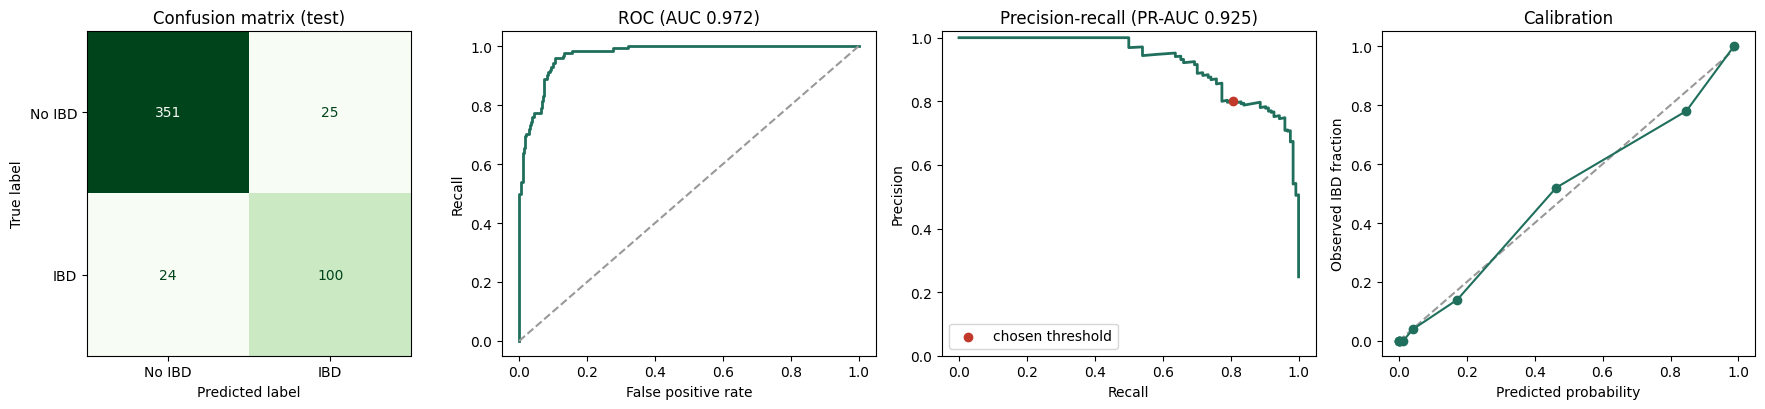

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
ConfusionMatrixDisplay.from_predictions(y_te, (p_te >= threshold).astype(int), display_labels=["No IBD", "IBD"],
                                        cmap="Greens", colorbar=False, ax=ax[0])
ax[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[1].plot(fpr, tpr, color=GREEN, lw=2); ax[1].plot([0, 1], [0, 1], "--", color=GREY)
ax[1].set(title=f"ROC (AUC {roc_auc_score(y_te, p_te):.3f})", xlabel="False positive rate", ylabel="Recall")
P, R, _ = precision_recall_curve(y_te, p_te)
ax[2].plot(R, P, color=GREEN, lw=2); ax[2].scatter([m["recall"]], [m["precision"]], color=RED, zorder=3, label="chosen threshold")
ax[2].set(title=f"Precision-recall (PR-AUC {average_precision_score(y_te, p_te):.3f})", xlabel="Recall",
          ylabel="Precision", ylim=(0, 1.02)); ax[2].legend(loc="lower left")
fp, mp = calibration_curve(y_te, p_te, n_bins=10, strategy="quantile")
ax[3].plot([0, 1], [0, 1], "--", color=GREY); ax[3].plot(mp, fp, "o-", color=GREEN)
ax[3].set(title="Calibration", xlabel="Predicted probability", ylabel="Observed IBD fraction")
plt.tight_layout(); plt.show()

In [14]:
display(Markdown("**Precision at each recall level (test set):**"))
precision_at_recall_table(y_te, p_te)

**Precision at each recall level (test set):**

,target_recall,recall,precision,threshold,accuracy
0,0.70,0.702,0.916,0.715,0.910
1,0.75,0.758,0.870,0.593,0.912
2,0.80,0.815,0.802,0.452,0.904
3,0.85,0.887,0.797,0.354,0.916
4,0.90,0.903,0.783,0.330,0.914
5,0.95,0.960,0.748,0.244,0.910
6,0.98,0.984,0.674,0.136,0.878


## 11. Final model and explainability (SHAP)
For deployment the chosen model is refit on **all 2,500 people** with the same tuning procedure and threshold.
SHAP shows how much each variable pushes a prediction up (red) or down (green), in log-odds.

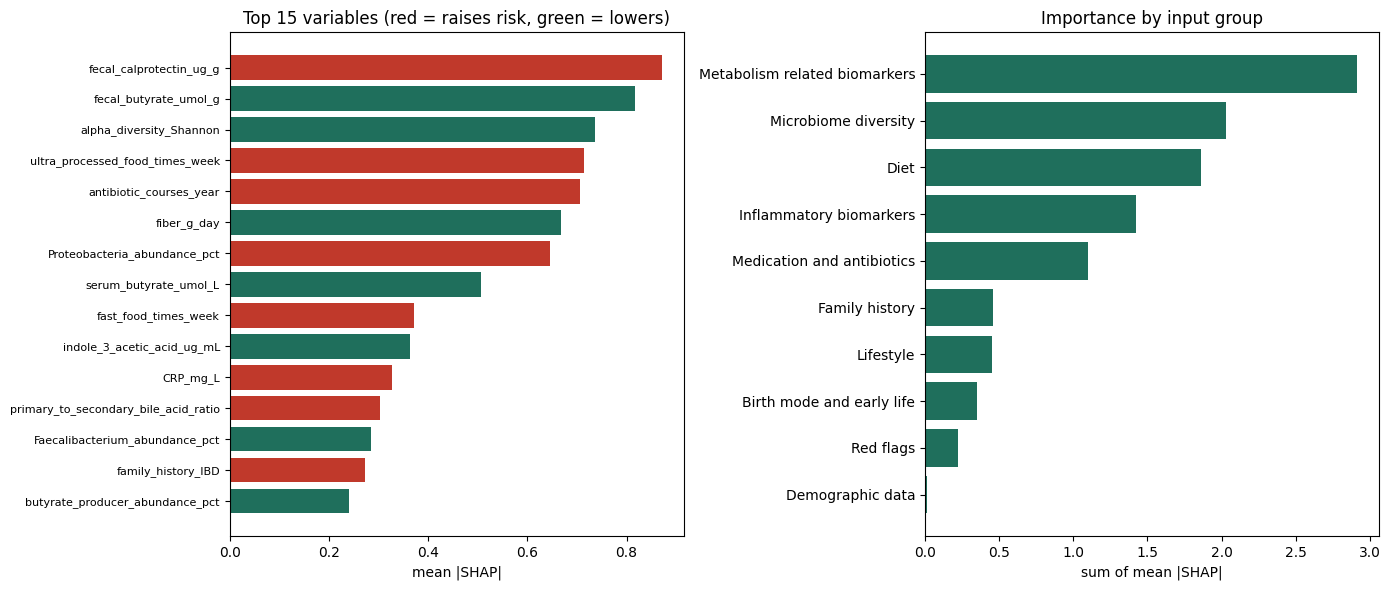

Sparse model uses 55 of 61 variables; dropped as uninformative: ['sex', 'BMI_kg_m2', 'sugary_drinks_times_week', 'fermented_food_times_week', 'fried_food_times_week', 'PSC_or_elevated_LFTs']


In [15]:
final_search = clone(searches[chosen]).fit(X, y)
final = final_search.best_estimator_
explainer = make_explainer(final, X)
sX = X.sample(300, random_state=SEED)
sv = explainer(sX)
mean_abs = pd.Series(np.abs(sv).mean(0), index=FEATURES).sort_values(ascending=False)
direction = {c: np.sign(np.nan_to_num(np.corrcoef(sX[c], sv[:, i])[0, 1])) for i, c in enumerate(FEATURES)}

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
t = mean_abs.head(15)[::-1]
ax[0].barh(t.index, t.values, color=[RED if direction[c] > 0 else GREEN for c in t.index])
ax[0].set(title="Top 15 variables (red = raises risk, green = lowers)", xlabel="mean |SHAP|")
ax[0].tick_params(axis="y", labelsize=8)
g = pd.Series({k: mean_abs[v].sum() for k, v in GROUPS.items()}).sort_values()
ax[1].barh(g.index, g.values, color=GREEN)
ax[1].set(title="Importance by input group", xlabel="sum of mean |SHAP|")
plt.tight_layout(); plt.show()

if hasattr(final[-1], "coef_"):
    dropped = [f for f, w in zip(FEATURES, final[-1].coef_[0]) if w == 0]
    print(f"Sparse model uses {61 - len(dropped)} of 61 variables; dropped as uninformative: {dropped}")

In [16]:
expected = {"fiber_g_day": -1, "alpha_diversity_Shannon": -1, "serum_butyrate_umol_L": -1, "fecal_butyrate_umol_g": -1,
            "vitamin_D_ng_mL": -1, "fecal_calprotectin_ug_g": 1, "Proteobacteria_abundance_pct": 1,
            "antibiotic_courses_year": 1}
pd.DataFrame([{"variable": f, "published evidence": "raises" if s > 0 else "lowers",
               "model": "raises" if direction[f] > 0 else "lowers",
               "agrees": "✅" if direction[f] == s else "❌"} for f, s in expected.items()]).style.hide(axis="index")

variable,published evidence,model,agrees
fiber_g_day,lowers,lowers,✅
alpha_diversity_Shannon,lowers,lowers,✅
serum_butyrate_umol_L,lowers,lowers,✅
fecal_butyrate_umol_g,lowers,lowers,✅
vitamin_D_ng_mL,lowers,lowers,✅
fecal_calprotectin_ug_g,raises,raises,✅
Proteobacteria_abundance_pct,raises,raises,✅
antibiotic_courses_year,raises,raises,✅


## 12. Save the model

In [17]:
from pathlib import Path
Path("artifacts").mkdir(exist_ok=True)
joblib.dump({
    "model": final, "model_name": chosen, "threshold": threshold, "tiers": TIERS,
    "feature_order": FEATURES, "groups": GROUPS,
    "defaults": {c: (raw[c].mode()[0] if raw[c].dtype == object else float(raw[c].median())) for c in FEATURES},
    "background": X.sample(200, random_state=SEED), "test_metrics": m, "disclaimer": DISCLAIMER,
}, "artifacts/model.joblib")
print("Saved artifacts/model.joblib")

Saved artifacts/model.joblib


## 13. Predict for a new person
Fill in the 61 variables by group, using readable values ("Yes"/"No", "Female", "First-degree relative", ...).
The result gives IBD / No IBD, the probability, a risk tier (Low < 20% ≤ Moderate < 50% ≤ High) and the top 5 reasons.

In [18]:
from predict import predict_ibd, _load
_load.cache_clear()  # pick up the model saved above

patient = {
    # Demographic data
    "age_years": 21, "sex": "Male", "BMI_kg_m2": 21.5,
    # Family history
    "family_history_IBD": "First-degree relative", "family_history_autoimmune": "No",
    # Diet
    "fiber_g_day": 10, "fast_food_times_week": 6, "ultra_processed_food_times_week": 12,
    "fruit_vegetable_servings_day": 1.5, "sugary_drinks_times_week": 8, "red_processed_meat_times_week": 3,
    "fermented_food_times_week": 0, "fish_times_week": 1, "dates_times_week": 2, "fried_food_times_week": 4,
    # Lifestyle
    "physical_activity_min_week": 60, "sedentary_hours_day": 9, "sleep_hours": 6, "sleep_quality": "Poor",
    "stress_level": "High", "smoking": "No", "vaping": "Yes",
    # Medication and antibiotics
    "antibiotic_courses_year": 4, "antibiotic_use_past_3_months": "Yes", "broad_spectrum_antibiotic": "Yes",
    "NSAID_use_times_month": 2, "PPI_use": "No", "childhood_antibiotic_exposure": "3+ courses/year",
    # Birth mode and early life
    "birth_mode": "Cesarean", "breastfeeding_months": 2, "childhood_GI_infection": "Yes", "childhood_infection_count": 2,
    # Microbiome diversity
    "alpha_diversity_Shannon": 2.0, "butyrate_producer_abundance_pct": 6, "Faecalibacterium_abundance_pct": 2.5,
    "Roseburia_abundance_pct": 1.0, "Bacteroides_abundance_pct": 20, "Proteobacteria_abundance_pct": 14,
    "Firmicutes_Bacteroidetes_ratio": 1.8,
    # Inflammatory biomarkers
    "fecal_calprotectin_ug_g": 320, "CRP_mg_L": 9, "vitamin_D_ng_mL": 14,
    # Metabolism related biomarkers
    "serum_butyrate_umol_L": 12, "fecal_butyrate_umol_g": 30, "primary_to_secondary_bile_acid_ratio": 2.6,
    "tryptophan_ug_mL": 12, "indole_3_acetic_acid_ug_mL": 1.8, "palmitic_acid_ug_mL": 125,
    "myristic_acid_ug_mL": 14, "arachidonic_acid_ug_mL": 65, "histidine_ug_mL": 11, "total_triglycerides_mg_dL": 140,
    # Red flags (1 = yes, 0 = no)
    "perianal_fistula_history": 1, "recurrent_aphthous_ulcers": 1, "erythema_nodosum_history": 0,
    "pyoderma_gangrenosum_history": 0, "hidradenitis_suppurativa_history": 0, "PSC_or_elevated_LFTs": 0,
    "unprovoked_VTE_history": 0, "appendectomy_history": 0, "tonsillectomy_history": 0,
}

r = predict_ibd(patient)
display(Markdown(f"### Prediction: **{r['prediction']}** — probability {r['probability']:.1%}, "
                 f"risk tier **{r['risk_tier']}** (threshold {r['threshold']:.1%})"))
display(pd.DataFrame(r["top_factors"]).style.hide(axis="index"))
display(Markdown(f"> ⚠️ {r['disclaimer']}"))

### Prediction: **IBD** — probability 100.0%, risk tier **High** (threshold 45.4%)

variable,value,effect,shap_log_odds
fecal_calprotectin_ug_g,320.000000,raises risk,4.140000
Proteobacteria_abundance_pct,14.000000,raises risk,3.136000
antibiotic_courses_year,4.000000,raises risk,2.427000
alpha_diversity_Shannon,2.000000,raises risk,2.061000
CRP_mg_L,9.000000,raises risk,1.974000


> ⚠️ Synthetic data only. SHAP explanations reflect the synthetic generation formula, not real biology. Do not present these explanations as clinical evidence or diagnostic reasoning.

## Summary
- **Best model:** chosen by nested cross-validation on PR-AUC (see section 8).
- **Threshold:** set on training data to balance precision and recall with recall ≥ 85%.
- **Test results** (section 10): precision, recall, accuracy and AUC on 500 people never used for training.
- **Explainability:** the strongest SHAP drivers agree in direction with published evidence.

> ⚠️ These results come from synthetic data. They show the pipeline works end to end (feasibility),
> not clinical accuracy. Real IRB-approved Saudi patient data is the next step.